# Ανάλυση Δεδομένων Αυτοκινήτων και Πρόβλεψη Κατανάλωσης Καυσίμου

Σε αυτό το project αναλύουμε δεδομένα 398 αυτοκινήτων με Python. Εξετάζουμε πώς χαρακτηριστικά όπως το βάρος, η ιπποδύναμη και ο κυβισμός σχετίζονται με την κατανάλωση καυσίμου.

Στη συνέχεια χρησιμοποιούμε απλή και πολλαπλή γραμμική παλινδρόμηση, πολυωνυμικά χαρακτηριστικά και Ridge Regression. Συγκρίνουμε τις προβλέψεις με R², MSE και 5-Fold Cross-Validation, ώστε να δούμε ποια προσέγγιση αποδίδει καλύτερα.

**Σύνολο δεδομένων:** UCI Auto MPG (μοντέλα αυτοκινήτων 1970–1982). **Μεταβλητή στόχος:** κατανάλωση καυσίμου σε L/100km.

In [37]:
# Εισαγωγή βιβλιοθήκης
import pandas as pd

# Ορισμός στηλών των δεδομενων
columns = [
    'mpg', 'cylinders', 'displacement',
    'horsepower', 'weight', 'acceleration',
    'model_year', 'origin', 'car_name'
]

# Ανάγνωση αρχείου από την python
df = pd.read_csv(
    'auto-mpg.data',
    sep=r'\s+',
    header=None,
    names=columns,
    na_values='?'
)

df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


## 1. Επισκόπηση δεδομένων

Αρχικά εξετάζουμε τις διαστάσεις, τους τύπους των στηλών, τις ελλείπουσες τιμές και τα βασικά στατιστικά χαρακτηριστικά του συνόλου δεδομένων.

In [38]:
print('Διαστάσεις δεδομένων:', df.shape)

print('\nΠληροφορίες δεδομένων:')
df.info()

print('\nΆθροισμα δεδομένων που λείπουν ανά στήλη:')
print(df.isnull().sum())

print('\nΒασικά στατιστικά αποτελέσματα:')
display(df.describe())

Διαστάσεις δεδομένων: (398, 9)

Πληροφορίες δεδομένων:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB

Άθροισμα δεδομένων που λείπουν ανά στήλη:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Βασικά στατιστικά αποτελέσματα:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000


## 2. Καθαρισμός δεδομένων

Παρατηρούμε ότι λείπουν 6 τιμές από τη στήλη `horsepower`. Για το αρχικό αυτό πείραμα τις αντικαθιστούμε με τον μέσο όρο της στήλης.

**Περιορισμός:** Ο μέσος όρος υπολογίζεται εδώ από όλο το dataset, πριν από τον διαχωρισμό των δεδομένων. Αυτό δημιουργεί μικρή διαρροή πληροφορίας (*data leakage*). Σε μια πιο αυστηρή υλοποίηση θα χρησιμοποιούσαμε `SimpleImputer` μέσα στο Pipeline. Η συγκεκριμένη επιλογή παραμένει στο notebook και αναφέρεται στα τελικά συμπεράσματα.

In [39]:
df[df['horsepower'].isnull()]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
32,25.0,4,98.0,NaN,2046.0,19.0,71,1,ford pinto
126,21.0,6,200.0,NaN,2875.0,17.0,74,1,ford maverick
330,40.9,4,85.0,NaN,1835.0,17.3,80,2,renault lecar deluxe
336,23.6,4,140.0,NaN,2905.0,14.3,80,1,ford mustang cobra
354,34.5,4,100.0,NaN,2320.0,15.8,81,2,renault 18i
374,23.0,4,151.0,NaN,3035.0,20.5,82,1,amc concord dl


In [40]:
#Εισάγουμε numpy
import numpy as np

In [41]:
# Μετατρέπουμε τη στήλη horsepower σε float και υπολογίζουμε στη στήλη αυτη (axis=0) τον μέσο όρο

avg_horsepower = df['horsepower'].astype('float').mean(axis=0)
print('average horsepower: ', avg_horsepower)

# Αντικατάσταση Nan με avg_horsepower
df['horsepower'] = df['horsepower'].replace(np.nan, avg_horsepower)
print(df['horsepower'].isnull().sum())

average horsepower:  104.46938775510205
0


### Μετατροπή μονάδων

Για να είναι πιο κατανοητά τα αποτελέσματα, μετατρέπουμε την κατανάλωση από μίλια ανά γαλόνι (`mpg`) σε λίτρα ανά 100 χιλιόμετρα (`L/100Km`) και το βάρος από λίβρες (`lbs`) σε κιλά (`kg`).

Κρατάμε τα δεκαδικά ψηφία στους υπολογισμούς. Αν χρειαστεί, στρογγυλοποιούμε μόνο την εμφάνιση των τιμών.

In [42]:
# Μετατροπή από mpg σε L/100Km
df['mpg'] = 235.215 / df['mpg']

# Μετατροπή lbs σε kg
df['weight'] = df['weight'] / 2.2046

# Αλλαγή ονόματος στήλης mpg
df.rename(columns = {'mpg': 'L/100Km'}, inplace=True)

#Έλεγχος αποτελεσμάτων
df.head()

,L/100Km,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,13.067500,8,307.0,130.0,1589.403974,12.0,70,1,chevrolet chevelle malibu
1,15.681000,8,350.0,165.0,1675.133811,11.5,70,1,buick skylark 320
2,13.067500,8,318.0,150.0,1558.559376,11.0,70,1,plymouth satellite
3,14.700938,8,304.0,150.0,1557.198585,12.0,70,1,amc rebel sst
4,13.836176,8,302.0,140.0,1564.456137,10.5,70,1,ford torino


# 3. Διερευνητική Ανάλυση Δεδομένων

Εξετάζουμε τις σχέσεις των χαρακτηριστικών των αυτοκινήτων με την κατανάλωση καυσίμου σε `L/100Km`. Οι συσχετίσεις αποτελούν αρχική ένδειξη για την επιλογή των χαρακτηριστικών και όχι απόδειξη αιτιώδους σχέσης.

In [43]:
# Συσχετίσεις όλων
df.corr(numeric_only=True)

,L/100Km,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
L/100Km,1.000000,0.839278,0.866631,0.850880,0.885219,-0.455750,-0.557427,-0.530213
cylinders,0.839278,1.000000,0.950721,0.838939,0.896017,-0.505419,-0.348746,-0.562543
displacement,0.866631,0.950721,1.000000,0.893646,0.932824,-0.543684,-0.370164,-0.609409
horsepower,0.850880,0.838939,0.893646,1.000000,0.860574,-0.684259,-0.411651,-0.453669
weight,0.885219,0.896017,0.932824,0.860574,1.000000,-0.417457,-0.306564,-0.581024
acceleration,-0.455750,-0.505419,-0.543684,-0.684259,-0.417457,1.000000,0.288137,0.205873
model_year,-0.557427,-0.348746,-0.370164,-0.411651,-0.306564,0.288137,1.000000,0.180662
origin,-0.530213,-0.562543,-0.609409,-0.453669,-0.581024,0.205873,0.180662,1.000000


In [44]:
# Συσχετίσεις μόνο με L/100Km
df.corr(numeric_only=True)['L/100Km']

L/100Km         1.000000
cylinders       0.839278
displacement    0.866631
horsepower      0.850880
weight          0.885219
acceleration   -0.455750
model_year     -0.557427
origin         -0.530213
Name: L/100Km, dtype: float64

### Παρατηρήσεις συσχέτισης

Παρατηρούμε ισχυρή θετική συσχέτιση της κατανάλωσης (`L/100Km`) με το βάρος (`weight`), τον κυβισμό (`displacement`), την ιπποδύναμη (`horsepower`) και τον αριθμό κυλίνδρων (`cylinders`).

Οι μεταβλητές `acceleration` και `model_year` παρουσιάζουν αρνητικές συσχετίσεις, αλλά αυτό δεν σημαίνει ότι δεν βοηθούν στις προβλέψεις. Η `origin` είναι κατηγορική μεταβλητή (1 = ΗΠΑ, 2 = Ευρώπη, 3 = Ιαπωνία), οπότε η συσχέτιση των αριθμητικών κωδικών της χρειάζεται προσοχή.

## 4. Οπτικοποίηση δεδομένων

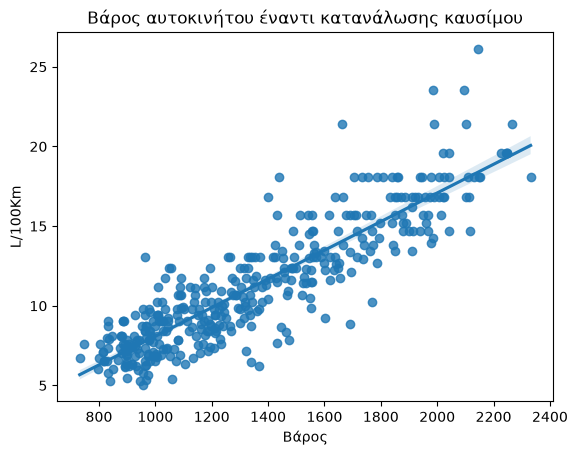

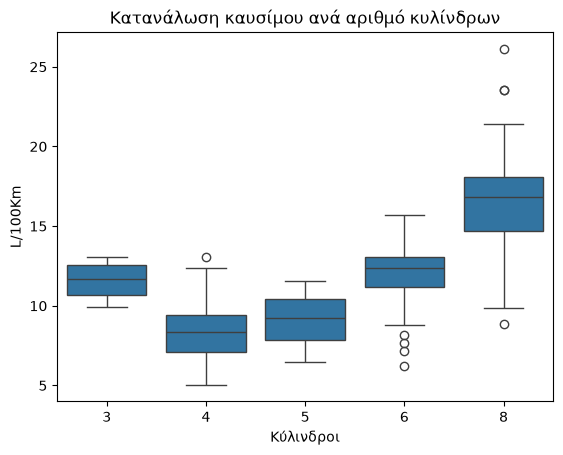

In [45]:
# Εγκατάσταση seaborn και matplotlib για γραφήματα
import seaborn as sns
import matplotlib.pyplot as plt

sns.regplot(x='weight', y='L/100Km', data=df)

plt.title('Βάρος αυτοκινήτου έναντι κατανάλωσης καυσίμου')
plt.xlabel('Βάρος')
plt.ylabel('L/100Km')
plt.show()

sns.boxplot(x='cylinders', y='L/100Km', data=df)

plt.title('Κατανάλωση καυσίμου ανά αριθμό κυλίνδρων')
plt.xlabel('Κύλινδροι')
plt.ylabel('L/100Km')
plt.show()

### Παρατηρήσεις στα γραφήματα

**Σχέση βάρους και κατανάλωσης:** Υπάρχει ισχυρή θετική συσχέτιση. Όσο αυξάνεται το βάρος, γενικά αυξάνεται και η κατανάλωση. Η σχέση φαίνεται περίπου γραμμική, με ορισμένες αποκλίσεις.

**Σχέση κυλίνδρων και κατανάλωσης:** Στο boxplot παρατηρούμε ότι τα αυτοκίνητα με περισσότερους κυλίνδρους έχουν συνήθως μεγαλύτερη κατανάλωση. Τα οκτακύλινδρα έχουν υψηλότερη διάμεση τιμή από τα τετρακύλινδρα.

# 5. Απλή γραμμική παλινδρόμηση

## 5.1 Αρχική εκπαίδευση στο σύνολο των δεδομένων

In [46]:
# %pip install scikit-learn 
# Εισάγουμε την γραμμικη παλινδρόμηση
from sklearn.linear_model import LinearRegression

lre = LinearRegression()
print(lre)

LinearRegression()


In [47]:
# Εκπαίδευση μοντέλου
lre.fit(df[['weight']], df['L/100Km'])

# Πρόβλεψη 5 τιμών του μοντέλου
Yhat=lre.predict(df[['weight']])
print('Πρώτες 5 προβλέψεις:', Yhat[0:5])

print('Συντελεστής παλινδρομησης:', lre.coef_)
print('Σταθερός ορος:', lre.intercept_)

Πρώτες 5 προβλέψεις: [13.38948786 14.16040405 13.11212119 13.09988442 13.16514717]
Συντελεστής παλινδρομησης: [0.00899239]
Σταθερός ορος: -0.9030536518793575


## 5.2 Εκπαίδευση στο 90% και αξιολόγηση στο υπόλοιπο 10%

In [48]:
# Δεδομένα βάρους για τα αυτοκινητα
x_data = df[['weight']]

# Δεδομένα που θέλουμε να προβλέψουμε
y_data = df['L/100Km']

In [49]:
# Εισαγωγή train_test_split
from sklearn.model_selection import train_test_split

# Διαχωρισμός δεδομενων σε train και test
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.1, random_state=1)

print('Αριθμός δειγμάτων test:', x_test.shape[0])
print('Αριθμός δειγμάτων train:', x_train.shape[0])

Αριθμός δειγμάτων test: 40
Αριθμός δειγμάτων train: 358


In [50]:
lre1 = LinearRegression()
lre1.fit(x_train, y_train)

# Πρόβλεψη 5 τιμών του μοντέλου
Yhat1=lre1.predict(x_train)
print('Προβλέψεις:', Yhat1[0:5])

print('Συντελεστής παλινδρομησης:', lre1.coef_)
print('Σταθερός ορος:', lre1.intercept_)

Προβλέψεις: [ 7.76797284 10.34606319 14.32181462  8.03029046 10.12063399]
Συντελεστής παλινδρομησης: [0.00903602]
Σταθερός ορος: -0.9458905873272023


### Παρατήρηση

Οι συντελεστές και οι σταθεροί όροι των δύο μοντέλων είναι πολύ κοντά, οπότε αναμένουμε οι ευθείες τους να σχεδόν ταυτίζονται.

### Οπτική σύγκριση των δύο μοντέλων

Στο επόμενο γράφημα εμφανίζουμε τις προβλέψεις των δύο ευθειών για **τα ίδια 40 αυτοκίνητα** του test set, μαζί με τις πραγματικές καταναλώσεις τους. Το μοντέλο του 100% έχει ήδη δει αυτά τα αυτοκίνητα, άρα το γράφημα δεν αποτελεί ανεξάρτητο έλεγχο γι' αυτό το μοντέλο.

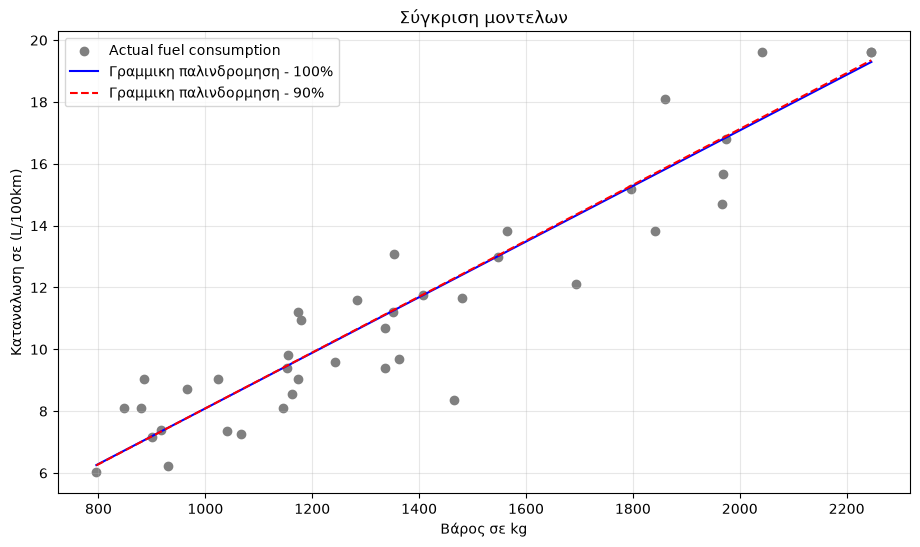

In [51]:
# Βαζουμε σε αυξουσα σειρα τις τιμές του βάρους στα δεδομενα
x_sorted = x_test.sort_values(by='weight')

# Διαστάσεις γραφήματος
plt.figure(figsize=(11, 6))

# Πραγματικές τιμές κατανάλωσης συνολου test
plt.scatter(x_test, y_test,
            color='gray',
            label='Actual fuel consumption')

# Μοντέλο εκπαιδευμένο στο 100%
plt.plot(x_sorted, lre.predict(x_sorted),
         color='blue', 
         label='Γραμμικη παλινδρομηση - 100%')

# Μοντέλο εκπαιδευμένο στο 90%
plt.plot(x_sorted, lre1.predict(x_sorted),
         color='red', linestyle='--',
         label='Γραμμικη παλινδορμηση - 90%')

# Στοιχεια γραφήματος
plt.xlabel('Βάρος σε kg')
plt.ylabel('Καταναλωση σε (L/100km)')
plt.title('Σύγκριση μοντελων')

# Προσθετα
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Τι παρατηρούμε;

Οι δύο ευθείες σχεδόν ταυτίζονται. Αυτό δείχνει ότι ο διαχωρισμός 90/10 δεν άλλαξε σημαντικά τους συντελεστές της απλής παλινδρόμησης. Υπάρχει ξεκάθαρη θετική σχέση μεταξύ βάρους και κατανάλωσης, αλλά αρκετά πραγματικά σημεία απέχουν από τις ευθείες. Γι' αυτό χρειαζόμαστε μετρικές αξιολόγησης.

### Αξιολόγηση μοντέλων: R² και MSE

In [52]:
# Εισάγουμε mse
from sklearn.metrics import mean_squared_error

# Υπολογισμός R^2 για κάθε μοντελο

# Μοντέλο γραμμικής παλινδρόμησης - 90%
R2_lre1_train = lre1.score(x_train, y_train)
R2_lre1_test = lre1.score(x_test, y_test)

print('Γραμμικη παλινδρόμηση - 90%')
print('Training R²:', R2_lre1_train)
print('Test R²:', R2_lre1_test)

# Μοντέλο γραμμικής παλινδρόμησης - 100%
R2_lre_train = lre.score(x_data, y_data)

print('\nΓραμμικη παλινδρόμηση - 100%')
print('Training R²:', R2_lre_train)

# Υπολογισμός MSE για κάθε μοντελο

# Μοντέλο γραμμικής παλινδρόμησης - 90%
lre1_weight_values_predict_train = lre1.predict(x_train)
lre1_weight_values_predict_test = lre1.predict(x_test)

lre1_mse_train = mean_squared_error(y_train, lre1_weight_values_predict_train)
lre1_mse_test = mean_squared_error(y_test, lre1_weight_values_predict_test)

print('\nΓραμμικη παλινδρόμηση - 90%')
print('Training MSE:', lre1_mse_train)
print('Test MSE:', lre1_mse_test)

# Μοντέλο γραμμικής παλινδρόμησης - 100%

lre_weight_values_predict = lre.predict(x_data)
lre_mse = mean_squared_error(y_data, lre_weight_values_predict)

print('\nΓραμμικη παλινδρόμηση - 100%')
print('MSE ολοκληρου συνολου:', lre_mse)


Γραμμικη παλινδρόμηση - 90%
Training R²: 0.7748552712654996
Test R²: 0.870561404112411

Γραμμικη παλινδρόμηση - 100%
Training R²: 0.7836118983544516

Γραμμικη παλινδρόμηση - 90%
Training MSE: 3.4552479658092867
Test MSE: 1.7816329153164276

Γραμμικη παλινδρόμηση - 100%
MSE ολοκληρου συνολου: 3.2865108179623963


Το μοντέλο του 90% έχει Training R² = 0,775 και Test R² = 0,871. Το Test MSE (1,782) είναι μικρότερο από το Training MSE (3,455). Αυτό σημαίνει ότι στα συγκεκριμένα 40 αυτοκίνητα ελέγχου οι προβλέψεις ήταν καλύτερες, όχι ότι το μοντέλο θα αποδίδει πάντα έτσι.

Το μοντέλο του 100% έχει R² = 0,784, αλλά αξιολογείται στα δεδομένα όπου εκπαιδεύτηκε. Για πιο αξιόπιστη εικόνα θα εξετάσουμε τη σταθερότητα των αποτελεσμάτων με Cross-Validation **μόνο στο training set**.

In [53]:
# Εισάγουμε cross-validation
from sklearn.model_selection import cross_val_score

Rcross = cross_val_score(lre, x_train, y_train, cv=5)

print('R² για κάθε fold:', Rcross)
print('Μέσο R²:', Rcross.mean())
print('Τυπική απόκλιση R²:', Rcross.std())

R² για κάθε fold: [0.77906806 0.78615157 0.77298011 0.81062764 0.71878316]
Μέσο R²: 0.7735221078655373
Τυπική απόκλιση R²: 0.0302116788746844


Με το 5-Fold Cross-Validation βρήκαμε μέσο R² = **0,774** και τυπική απόκλιση **0,030**. Η επίδοση παραμένει σχετικά σταθερή στους πέντε διαχωρισμούς και δείχνει ότι το βάρος είναι χρήσιμο για την πρόβλεψη της κατανάλωσης. Δεν μπορούμε όμως να θεωρήσουμε ότι το μοντέλο του 100% έχει την ίδια ικανότητα γενίκευσης, επειδή δεν αξιολογήθηκε σε ανεξάρτητα δεδομένα.

Στη συνέχεια δοκιμάζουμε περισσότερα χαρακτηριστικά, για να εξετάσουμε αν βελτιώνουν τις προβλέψεις.

# 6. Πολλαπλή γραμμική παλινδρόμηση

Θέλουμε να εξετάσουμε αν περισσότερες πληροφορίες για κάθε αυτοκίνητο βελτιώνουν την πρόβλεψη της κατανάλωσης. Δοκιμάζουμε δύο περιπτώσεις:

1. **Τέσσερα χαρακτηριστικά με υψηλή συσχέτιση:** `cylinders`, `displacement`, `horsepower`, `weight`.
2. **Όλα τα κατάλληλα χαρακτηριστικά:** τα παραπάνω μαζί με `acceleration`, `model_year` και την κατηγορική `origin`, την οποία μετατρέπουμε σε δύο dummy στήλες με `pd.get_dummies()`.

Και στις δύο περιπτώσεις χρησιμοποιούμε τον ίδιο διαχωρισμό 90/10 και 5-Fold Cross-Validation στο training set.

In [54]:
# Κατασκευή μοντέλου με cylinders, displacement, horsepower, weight

# Εκπαίδευση
multi_lre = LinearRegression()
x_train_multi_lre, x_test_multi_lre, y_train_multi_lre, y_test_multi_lre = train_test_split(df[['cylinders', 'displacement', 'horsepower', 'weight']], df['L/100Km'], test_size=0.1, random_state=1)
multi_lre.fit(x_train_multi_lre, y_train_multi_lre)

# Cross_Validation
Rcross_multi_lre = cross_val_score(multi_lre, x_train_multi_lre, y_train_multi_lre, cv=5)

# Υπολογισμός R^2, MSE
r2_multi_lre_train = multi_lre.score(x_train_multi_lre, y_train_multi_lre)
r2_multi_lre_test = multi_lre.score(x_test_multi_lre, y_test_multi_lre)

# Training MSE
y_train_multi_lre_predict = multi_lre.predict(x_train_multi_lre)
mse_train_multi_lre = mean_squared_error(y_train_multi_lre, y_train_multi_lre_predict)

# Test MSE
y_test_multi_lre_predict = multi_lre.predict(x_test_multi_lre)
mse_test_multi_lre = mean_squared_error(y_test_multi_lre, y_test_multi_lre_predict)


# Εκτύπωση
print('R^2 πολλαπλής γραμμικής παλινδρόμησης train', r2_multi_lre_train)
print('R^2 πολλαπλής γραμμικής παλινδρόμησης test', r2_multi_lre_test)
print('MSE πολλαπλής γραμμικής παλινδρόμησης train', mse_train_multi_lre)
print('MSE πολλαπλής γραμμικής παλινδρόμησης test', mse_test_multi_lre)
print('\nCross_validation:')
print('R² για κάθε fold:', Rcross_multi_lre)
print('Μέσο R²:', Rcross_multi_lre.mean())
print('Τυπική απόκλιση R²:', Rcross_multi_lre.std())

R^2 πολλαπλής γραμμικής παλινδρόμησης train 0.810209006829378
R^2 πολλαπλής γραμμικής παλινδρόμησης test 0.8823578325542447
MSE πολλαπλής γραμμικής παλινδρόμησης train 2.912681752611813
MSE πολλαπλής γραμμικής παλινδρόμησης test 1.6192632214007283

Cross_validation:
R² για κάθε fold: [0.83449912 0.80327373 0.78908352 0.79145921 0.77214423]
Μέσο R²: 0.798091962034955
Τυπική απόκλιση R²: 0.02074011614208266


### 6.2 Μοντέλο με όλα τα κατάλληλα χαρακτηριστικά

Επαναλαμβάνουμε την ίδια διαδικασία, αυτή τη φορά με περισσότερα χαρακτηριστικά. Η `origin` μετατρέπεται σε δύο στήλες (`origin_2`, `origin_3`). Με `drop_first=True`, τα αυτοκίνητα των ΗΠΑ αντιστοιχούν σε (0, 0), της Ευρώπης σε (1, 0) και της Ιαπωνίας σε (0, 1).

In [55]:
# Κατασκευή μοντέλου με ολες τις αριθμητικές στηλες

# Εκπαίδευση
multi_x_data = df.select_dtypes(include='number').drop('L/100Km', axis=1)
multi_x_data = pd.get_dummies(multi_x_data, columns=['origin'], drop_first=True, dtype=int)
multi_y_data = df['L/100Km']
multi1_lre = LinearRegression()
x_train_multi1_lre, x_test_multi1_lre, y_train_multi1_lre, y_test_multi1_lre = train_test_split(multi_x_data, multi_y_data, test_size=0.1, random_state=1)
multi1_lre.fit(x_train_multi1_lre, y_train_multi1_lre)

# Cross_Validation
Rcross_multi1_lre = cross_val_score(multi1_lre, x_train_multi1_lre, y_train_multi1_lre, cv=5)

# Υπολογισμός R^2, MSE
r2_multi1_lre_train = multi1_lre.score(x_train_multi1_lre, y_train_multi1_lre)
r2_multi1_lre_test = multi1_lre.score(x_test_multi1_lre, y_test_multi1_lre)

# Training MSE
y_train_multi1_lre_predict = multi1_lre.predict(x_train_multi1_lre)
mse_train_multi1_lre = mean_squared_error(y_train_multi1_lre, y_train_multi1_lre_predict)

# Test MSE
y_test_multi1_lre_predict = multi1_lre.predict(x_test_multi1_lre)
mse_test_multi1_lre = mean_squared_error(y_test_multi1_lre, y_test_multi1_lre_predict)


# Εκτύπωση
print('R^2 πολλαπλής γραμμικής παλινδρόμησης train', r2_multi1_lre_train)
print('R^2 πολλαπλής γραμμικής παλινδρόμησης test', r2_multi1_lre_test)
print('MSE πολλαπλής γραμμικής παλινδρόμησης train', mse_train_multi1_lre)
print('MSE πολλαπλής γραμμικής παλινδρόμησης test', mse_test_multi1_lre)
print('\nCross_validation:')
print('R² για κάθε fold:', Rcross_multi1_lre)
print('Μέσο R²:', Rcross_multi1_lre.mean())
print('Τυπική απόκλιση R²:', Rcross_multi1_lre.std())

R^2 πολλαπλής γραμμικής παλινδρόμησης train 0.8831129100815017
R^2 πολλαπλής γραμμικής παλινδρόμησης test 0.9229219123288425
MSE πολλαπλής γραμμικής παλινδρόμησης train 1.793841152490505
MSE πολλαπλής γραμμικής παλινδρόμησης test 1.0609266664468413

Cross_validation:
R² για κάθε fold: [0.88928434 0.87246942 0.87547683 0.88877263 0.84749235]
Μέσο R²: 0.8746991147239556
Τυπική απόκλιση R²: 0.015209055418977822


### Σύγκριση πολλαπλής γραμμικής παλινδρόμησης

Με τέσσερα χαρακτηριστικά βρήκαμε μέσο CV R² = **0,798**, ενώ με όλα τα κατάλληλα χαρακτηριστικά **0,875**. Η δεύτερη προσέγγιση είχε επίσης μικρή τυπική απόκλιση (0,015). Άρα, στη συγκεκριμένη αξιολόγηση, οι επιπλέον μεταβλητές βελτίωσαν αισθητά τις προβλέψεις.

Αυτό είναι σημαντικό: η ισχυρή συσχέτιση μιας μεταβλητής με τον στόχο δεν είναι το μοναδικό κριτήριο χρησιμότητας.

# 7. Πολυωνυμική παλινδρόμηση

Εξετάζουμε αν η προσθήκη πολυωνυμικών όρων βελτιώνει τις προβλέψεις. Δοκιμάζουμε βαθμούς 1–4 με 5-Fold Cross-Validation, χωριστά για τις δύο ομάδες χαρακτηριστικών.

### 7.1 Τέσσερα χαρακτηριστικά

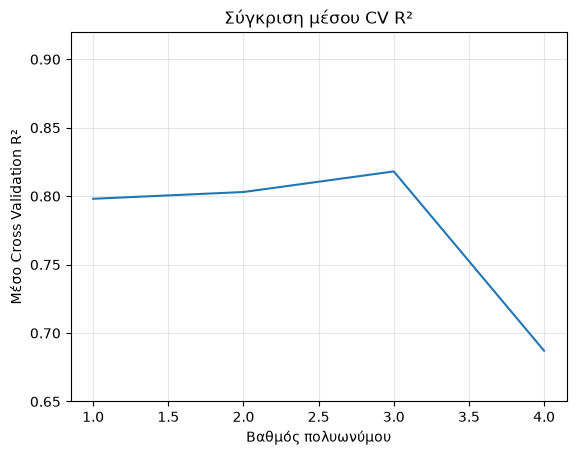

In [56]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

Rsqu_cv = []

order = [1, 2, 3, 4]

for n in order:

    pr = Pipeline([
        ('poly', PolynomialFeatures(degree=n, include_bias=False)),
        ('linear', LinearRegression())
        ])

    scores = cross_val_score(pr, x_train_multi_lre, y_train_multi_lre, cv=5,)

    Rsqu_cv.append(scores.mean())
    
plt.plot(order, Rsqu_cv)
plt.xlabel('Βαθμός πολυωνύμου')
plt.ylabel('Μέσο Cross Validation R²')
plt.title('Σύγκριση μέσου CV R²')
plt.ylim(0.65, 0.92)
plt.grid(alpha=0.3)
plt.show()

### 7.2 Όλα τα κατάλληλα χαρακτηριστικά

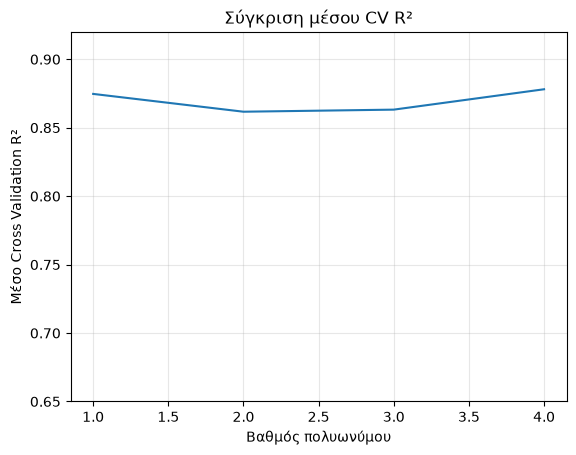

In [57]:
Rsqu_cv = []
order = [1, 2, 3, 4]

for n in order:
    pr = Pipeline([
        ('poly', PolynomialFeatures(degree=n, include_bias=False)),
        ('linear', LinearRegression())
    ])

    scores = cross_val_score(pr, x_train_multi1_lre, y_train_multi1_lre, cv=5)
    Rsqu_cv.append(scores.mean())

plt.plot(order, Rsqu_cv)
plt.xlabel('Βαθμός πολυωνύμου')
plt.ylabel('Μέσο Cross Validation R²')
plt.title('Σύγκριση μέσου CV R²')
plt.ylim(0.65, 0.92)
plt.grid(alpha=0.3)
plt.show()

### Παρατήρηση για την πολυωνυμική παλινδρόμηση

**Με 4 χαρακτηριστικά**, το μέσο CV R² αυξάνεται έως τον 3ο βαθμό και μειώνεται έντονα στον 4ο. Αυτό είναι ένδειξη ότι η μεγαλύτερη πολυπλοκότητα μπορεί να δυσκολεύει τη γενίκευση ή να προκαλεί αριθμητική αστάθεια.

**Με όλα τα χαρακτηριστικά**, ο 4ος βαθμός φαίνεται να είναι ελάχιστα υψηλότερος από την πολλαπλή γραμμική παλινδρόμηση. Όμως οι αρχικές 8 στήλες γίνονται **494 πολυωνυμικά χαρακτηριστικά**. Επομένως, χωρίς Ridge, η επιπλέον πολυπλοκότητα δεν φαίνεται να προσφέρει ουσιαστικό όφελος.

# 8. Παλινδρόμηση Ridge

Η Ridge περιορίζει το μέγεθος των συντελεστών μέσω κανονικοποίησης (*regularization*). Τη δοκιμάζουμε επειδή τα χαρακτηριστικά είναι έντονα συσχετισμένα μεταξύ τους και οι πολυωνυμικοί όροι αυξάνουν σημαντικά την πολυπλοκότητα.

Αρχικά εξετάζουμε τέσσερα χαρακτηριστικά (`cylinders`, `displacement`, `horsepower`, `weight`). Για κάθε πολυωνυμικό βαθμό δοκιμάζουμε διαφορετικές τιμές `alpha` και υπολογίζουμε το μέσο CV R².

Βαθμός 1: best alpha = 13.738237958832638,
CV R² = 0.8007979249167896
Βαθμός 2: best alpha = 0.04520353656360243,
CV R² = 0.8060332661100448
Βαθμός 3: best alpha = 0.001,
CV R² = 0.8175026665640873
Βαθμός 4: best alpha = 0.0016102620275609393,
CV R² = 0.821670978999505


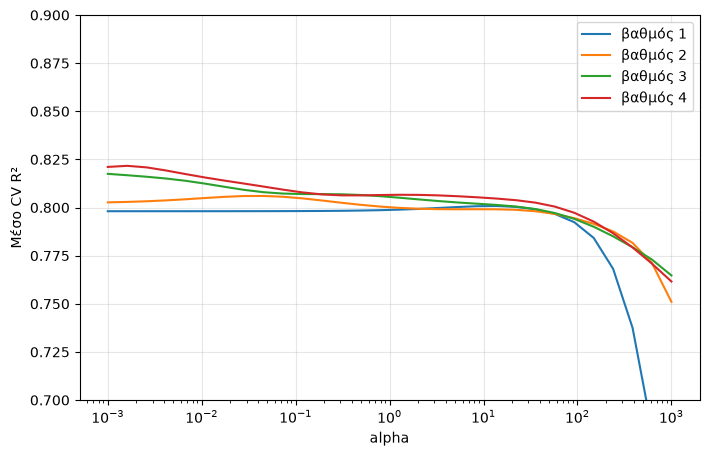

In [58]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
alphas = np.logspace(-3, 3, 30)   # 30 τιμες από 10^-3 έως 10^3

# Έλεγχος για κάθε βαθμό
plt.figure(figsize=(8, 5))
for n in [1, 2, 3, 4]:
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=n, include_bias=False)),
        ('scaler', StandardScaler()),
        ('ridge', Ridge())
    ])
    grid = GridSearchCV(pipe, {'ridge__alpha': alphas}, cv=5)
    grid.fit(x_train_multi_lre, y_train_multi_lre)

    print(f'Βαθμός {n}: best alpha = {grid.best_params_["ridge__alpha"]},')
    print(f'CV R² = {grid.best_score_}')
    plt.semilogx(alphas, grid.cv_results_['mean_test_score'], label=f'βαθμός {n}')

# Γράφημα με λογαριθμική κλίμακα στον άξονα alpha
plt.xlabel('alpha')
plt.ylabel('Μέσο CV R²')
plt.ylim(0.7, 0.9)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Παρατήρηση:** Με τις τέσσερις μεταβλητές, η Ridge έδωσε μέσο CV R² από περίπου 0,801 (1ος βαθμός) έως 0,822 (4ος βαθμός). Παραμένει επομένως χαμηλότερα από τη γραμμική παλινδρόμηση με όλα τα κατάλληλα χαρακτηριστικά (0,875). Για ορισμένους βαθμούς, το καλύτερο `alpha` βρίσκεται κοντά στο κατώτερο όριο της αναζήτησης, κάτι που θα άξιζε να διερευνηθεί με μεγαλύτερο εύρος τιμών σε μελλοντική ανάλυση.

### 8.2 Ridge με όλα τα κατάλληλα χαρακτηριστικά

Επαναλαμβάνουμε την αναζήτηση και με όλες τις κατάλληλες μεταβλητές, ώστε να εξετάσουμε αν το επιπλέον σύνολο πληροφοριών βελτιώνει την απόδοση.

Βαθμός 1: best alpha = 3.2903445623126677,
CV R² = 0.8754834264663078
Βαθμός 2: best alpha = 0.11721022975334805,
CV R² = 0.8864811223372451
Βαθμός 3: best alpha = 0.11721022975334805,
CV R² = 0.8932277746613847
Βαθμός 4: best alpha = 0.7880462815669912,
CV R² = 0.8954642779221895


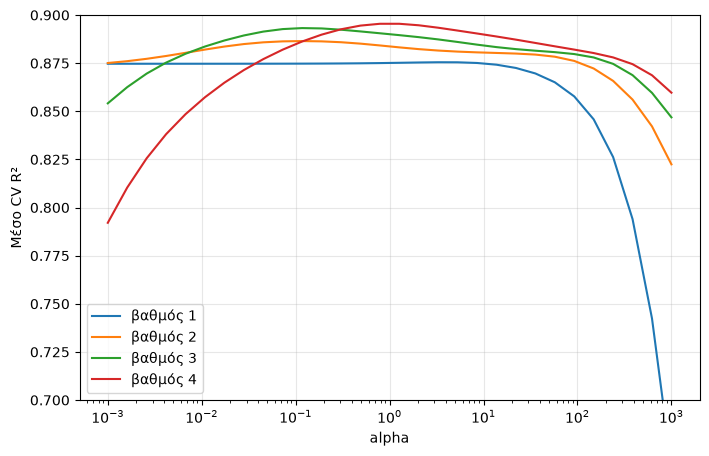

In [59]:
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
alphas = np.logspace(-3, 3, 30)   # 30 τιμες από 10^-3 έως 10^3

# Έλεγχος για κάθε βαθμό
plt.figure(figsize=(8, 5))
for n in [1, 2, 3, 4]:
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=n, include_bias=False)),
        ('scaler', StandardScaler()),
        ('ridge', Ridge())
    ])
    grid = GridSearchCV(pipe, {'ridge__alpha': alphas}, cv=5)
    grid.fit(x_train_multi1_lre, y_train_multi1_lre)

    print(f'Βαθμός {n}: best alpha = {grid.best_params_["ridge__alpha"]},')
    print(f'CV R² = {grid.best_score_}')
    plt.semilogx(alphas, grid.cv_results_['mean_test_score'], label=f'βαθμός {n}')

# Γράφημα με λογαριθμική κλίμακα στον άξονα alpha
plt.xlabel('alpha')
plt.ylabel('Μέσο CV R²')
plt.ylim(0.7, 0.9)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 8.3 Επιλογή υπερπαραμέτρων με GridSearchCV

Το Ridge 4ου βαθμού έχει το υψηλότερο μέσο CV R² μεταξύ των συνδυασμών που εξετάσαμε. Η αναζήτηση δοκιμάζει **4 βαθμούς × 30 τιμές alpha = 120 συνδυασμούς**, με 5 folds για κάθε συνδυασμό. Θα αξιολογήσουμε στη συνέχεια το καλύτερο Pipeline και στο test set, λαμβάνοντας υπόψη ότι έχουμε ήδη κοιτάξει το test set σε προηγούμενα πειράματα.

In [60]:
# Παράμετροι dictionary 120 total
param_grid = {
    'poly__degree': [1, 2, 3, 4],
    'ridge__alpha': alphas
}

# Pipe
pipe = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

# Εκπαίδευση
grid = GridSearchCV(pipe, param_grid, cv=5, scoring='r2')
grid.fit(x_train_multi1_lre, y_train_multi1_lre)

# Εκτύπωση
print(grid.best_params_, grid.best_score_)
best_model = grid.best_estimator_

{'poly__degree': 4, 'ridge__alpha': np.float64(0.7880462815669912)} 0.8954642779221895


### 8.4 Αξιολόγηση του επιλεγμένου μοντέλου στο test set

In [61]:
ridge_test = best_model.predict(x_test_multi1_lre)

# Υπολογισμός R²
ridge_r2_test = best_model.score(x_test_multi1_lre, y_test_multi1_lre)

# Υπολογισμός MSE
ridge_mse_test = mean_squared_error(y_test_multi1_lre, ridge_test)

# Εκτύπωση
print('Ridge CV R²:', grid.best_score_)
print('Ridge Test R²:', ridge_r2_test)
print('Ridge Test MSE:', ridge_mse_test)

Ridge CV R²: 0.8954642779221895
Ridge Test R²: 0.9326797081177887
Ridge Test MSE: 0.9266173436416066


# 9. Σύγκριση μοντέλων και τελικά συμπεράσματα

Συγκεντρώνουμε τις μετρικές των μοντέλων και εξετάζουμε τι βελτίωσε τις προβλέψεις, πού εμφανίζονται μεγαλύτερα σφάλματα και αν το Ridge έχει σταθερό πλεονέκτημα.

## 9.1 Πίνακας σύγκρισης

Ο μέσος όρος και η τυπική απόκλιση του **CV R²** προκύπτουν από τα 5 folds του training set. Τα **Test R²**, **Test MSE** και **Test RMSE** περιγράφουν την επίδοση στα 40 αυτοκίνητα ελέγχου.

Το **RMSE = √MSE** εκφράζεται σε L/100km και είναι πιο εύκολο να το κατανοήσουμε από το MSE, το οποίο εκφράζεται σε (L/100km)². Επειδή κοιτάξαμε το test set και σε προηγούμενες δοκιμές, δεν το αντιμετωπίζουμε ως εντελώς ανεπηρέαστο από τη διαδικασία επιλογής.

In [62]:
# Πίνακας σύγκρισης των μοντέλων
ridge_cv_std = grid.cv_results_['std_test_score'][grid.best_index_]

results = pd.DataFrame({
    'Μοντέλο': ['Γραμμική (weight)', 'Πολλαπλή (4 μεταβλητές)', 'Πολλαπλή (όλες)', 'Ridge βαθμού 4 (όλες)'],
    'CV R² (μέσο)': [Rcross.mean(), Rcross_multi_lre.mean(), Rcross_multi1_lre.mean(), grid.best_score_],
    'CV R² (τυπ. απόκλιση)': [Rcross.std(), Rcross_multi_lre.std(), Rcross_multi1_lre.std(), ridge_cv_std],
    'Test R²': [R2_lre1_test, r2_multi_lre_test, r2_multi1_lre_test, ridge_r2_test],
    'Test MSE': [lre1_mse_test, mse_test_multi_lre, mse_test_multi1_lre, ridge_mse_test],
})
results['Test RMSE'] = np.sqrt(results['Test MSE'])

display(results.round(3))

,Μοντέλο,CV R² (μέσο),CV R² (τυπ. απόκλιση),Test R²,Test MSE,Test RMSE
0,Γραμμική (weight),0.774,0.030,0.871,1.782,1.335
1,Πολλαπλή (4 μεταβλητές),0.798,0.021,0.882,1.619,1.273
2,Πολλαπλή (όλες),0.875,0.015,0.923,1.061,1.030
3,Ridge βαθμού 4 (όλες),0.895,0.008,0.933,0.927,0.963


Στο επόμενο γράφημα οι μπάρες σφάλματος δείχνουν την τυπική απόκλιση του CV R² ανάμεσα στα folds. Ο κατακόρυφος άξονας ξεκινά από 0,7 και όχι από 0, επομένως οι οπτικές διαφορές φαίνονται μεγαλύτερες.

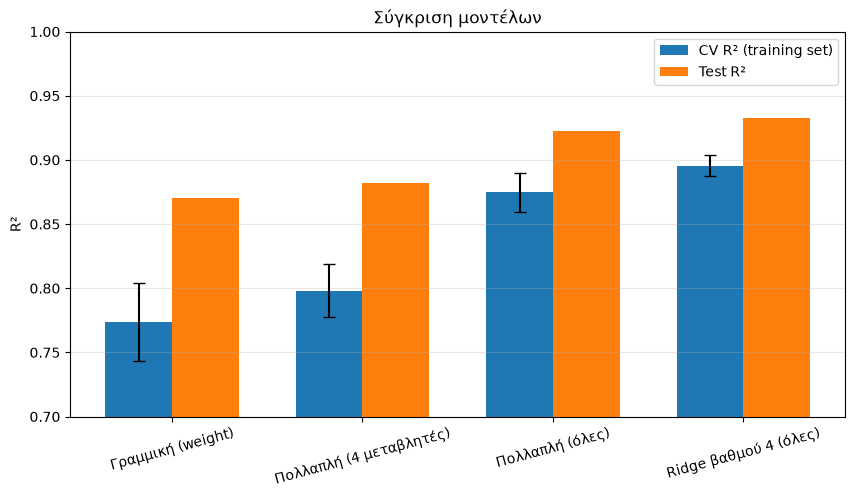

In [63]:
# Γράφημα σύγκρισης μοντέλων
x_pos = np.arange(len(results))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x_pos - width/2, results['CV R² (μέσο)'], width,
        yerr=results['CV R² (τυπ. απόκλιση)'], capsize=4, label='CV R² (training set)')
plt.bar(x_pos + width/2, results['Test R²'], width, label='Test R²')
plt.xticks(x_pos, results['Μοντέλο'], rotation=15)
plt.ylim(0.7, 1.0)
plt.ylabel('R²')
plt.title('Σύγκριση μοντέλων')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

## 9.2 Τι πρόσφεραν οι επιπλέον μεταβλητές;

Η μεγαλύτερη αύξηση στο μέσο CV R² προέκυψε όταν περάσαμε από τις τέσσερις ισχυρά συσχετισμένες μεταβλητές (0,798) σε όλα τα κατάλληλα χαρακτηριστικά (0,875). Με το επόμενο heatmap εξετάζουμε ποιες μεταβλητές σχετίζονται έντονα μεταξύ τους.

Όταν τα χαρακτηριστικά έχουν υψηλή μεταξύ τους συσχέτιση (*πολυσυγγραμμικότητα*), οι συντελεστές της γραμμικής παλινδρόμησης μπορεί να είναι ασταθείς. Αυτός είναι ένας λόγος που δοκιμάσαμε και Ridge.

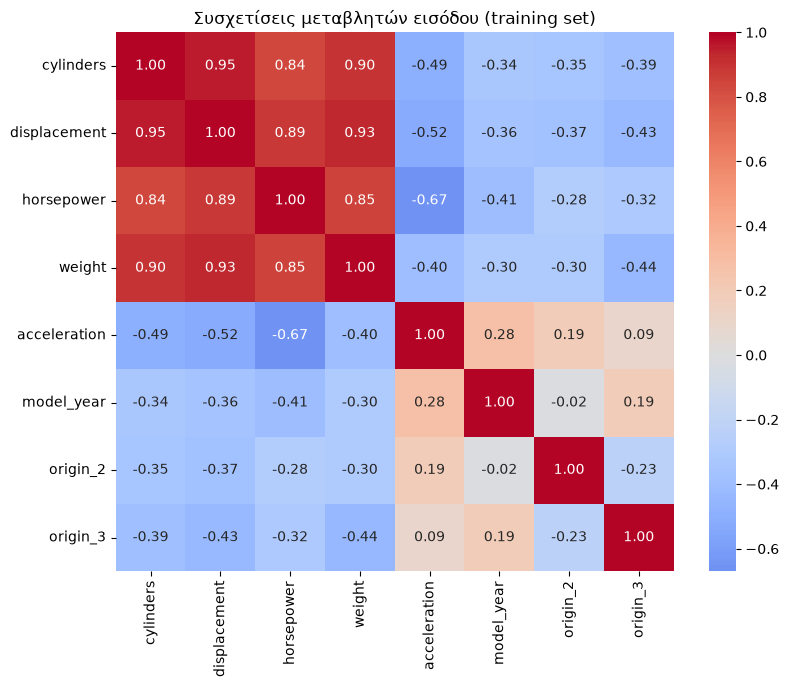

In [64]:
# Συσχετίσεις ανάμεσα στις μεταβλητές εισόδου
plt.figure(figsize=(9, 7))
sns.heatmap(x_train_multi1_lre.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Συσχετίσεις μεταβλητών εισόδου (training set)')
plt.show()

Στη συνέχεια τυποποιούμε τα χαρακτηριστικά (μέσος 0 και τυπική απόκλιση 1) και εξετάζουμε τους συντελεστές της γραμμικής παλινδρόμησης. Έτσι μπορούμε να συγκρίνουμε ευκολότερα το μέγεθός τους, πάντα με επιφύλαξη λόγω της συσχέτισης των μεταβλητών.

Οι συντελεστές περιγράφουν σχέσεις μέσα στο μοντέλο και **δεν αποδεικνύουν αιτιότητα**.

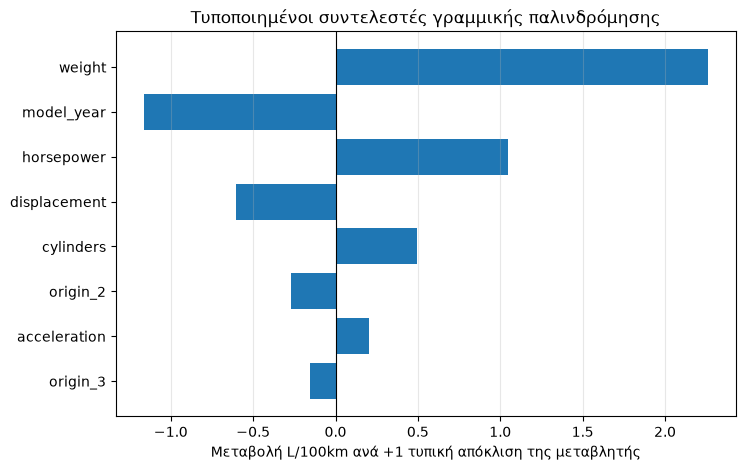

weight          2.258
model_year     -1.163
horsepower      1.048
displacement   -0.603
cylinders       0.492
origin_2       -0.271
acceleration    0.206
origin_3       -0.152
dtype: float64


In [65]:
# Γραμμική παλινδρόμηση με τυποποιημένες μεταβλητές (για ερμηνεία)
lin_scaled = Pipeline([
    ('scaler', StandardScaler()),
    ('linear', LinearRegression())
])
lin_scaled.fit(x_train_multi1_lre, y_train_multi1_lre)

coefs = pd.Series(lin_scaled.named_steps['linear'].coef_, index=x_train_multi1_lre.columns)
sorted_coefs = coefs.sort_values(key=abs)

plt.figure(figsize=(8, 5))
plt.barh(sorted_coefs.index, sorted_coefs.values)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Μεταβολή L/100km ανά +1 τυπική απόκλιση της μεταβλητής')
plt.title('Τυποποιημένοι συντελεστές γραμμικής παλινδρόμησης')
plt.grid(axis='x', alpha=0.3)
plt.show()

print(coefs.sort_values(key=abs, ascending=False).round(3))

### Τι παρατηρούμε στους συντελεστές;

Μετά την τυποποίηση, ο μεγαλύτερος θετικός συντελεστής είναι του `weight` (**2,258**), ενώ το `model_year` έχει έντονο αρνητικό συντελεστή (**−1,163**). Η `horsepower` έχει επίσης θετικό συντελεστή (**1,048**).

Αυτό δείχνει ότι το βάρος και το έτος του μοντέλου περιέχουν χρήσιμη πληροφορία για την κατανάλωση. Όμως τα `weight`, `horsepower`, `displacement` και `cylinders` έχουν μεγάλη συσχέτιση μεταξύ τους, επομένως οι συντελεστές χρειάζονται προσοχή και **δεν αποτελούν απόδειξη αιτιότητας**. Οι `origin_2` και `origin_3` συγκρίνονται με την προέλευση 1 (ΗΠΑ).

## 9.3 Έλεγχος των σφαλμάτων πρόβλεψης

Το **υπόλοιπο (residual)** είναι η πραγματική κατανάλωση μείον την προβλεπόμενη. Στο γράφημα εξετάζουμε αν τα σφάλματα βρίσκονται περίπου γύρω από το μηδέν ή αν εμφανίζεται συστηματικό μοτίβο. Επίσης, εντοπίζουμε τα πέντε αυτοκίνητα με το μεγαλύτερο απόλυτο σφάλμα.

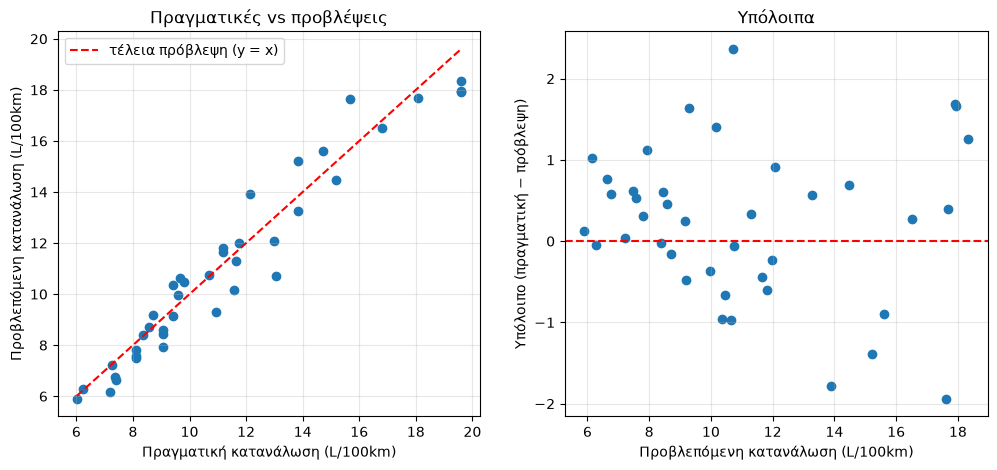

In [66]:
# Πραγματικές vs προβλεπόμενες τιμές και υπόλοιπα (test set)
y_pred = best_model.predict(x_test_multi1_lre)
residuals = y_test_multi1_lre - y_pred

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(y_test_multi1_lre, y_pred)
lims = [y_test_multi1_lre.min(), y_test_multi1_lre.max()]
ax[0].plot(lims, lims, 'r--', label='τέλεια πρόβλεψη (y = x)')
ax[0].set_xlabel('Πραγματική κατανάλωση (L/100km)')
ax[0].set_ylabel('Προβλεπόμενη κατανάλωση (L/100km)')
ax[0].set_title('Πραγματικές vs προβλέψεις')
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].scatter(y_pred, residuals)
ax[1].axhline(0, color='r', linestyle='--')
ax[1].set_xlabel('Προβλεπόμενη κατανάλωση (L/100km)')
ax[1].set_ylabel('Υπόλοιπο (πραγματική − πρόβλεψη)')
ax[1].set_title('Υπόλοιπα')
ax[1].grid(alpha=0.3)

plt.show()

In [67]:
# Τα 5 αυτοκίνητα του test set με το μεγαλύτερο σφάλμα
errors = pd.DataFrame({
    'car_name': df.loc[y_test_multi1_lre.index, 'car_name'],
    'Πραγματική': y_test_multi1_lre,
    'Πρόβλεψη': y_pred,
    'Υπόλοιπο': residuals
})
errors.sort_values(by='Υπόλοιπο', key=abs, ascending=False).head(5).round(2)

,car_name,Πραγματική,Πρόβλεψη,Υπόλοιπο
174,ford pinto,13.07,10.70,2.36
5,ford galaxie 500,15.68,17.62,-1.94
250,dodge diplomat,12.12,13.90,-1.78
106,oldsmobile vista cruiser,19.60,17.91,1.69
95,buick electra 225 custom,19.60,17.94,1.66


### Παρατήρηση για τα σφάλματα

Οι περισσότερες προβλέψεις βρίσκονται σχετικά κοντά στις πραγματικές τιμές, αλλά υπάρχουν και μεγαλύτερες αποκλίσεις. Για παράδειγμα, στο test set το **Ford Pinto** είχε πραγματική κατανάλωση **13,07 L/100km**, ενώ το μοντέλο προέβλεψε περίπου **10,70 L/100km** (σφάλμα **+2,36 L/100km**). Αυτό δείχνει ότι ακόμη και το καλύτερο μοντέλο δεν προβλέπει το ίδιο καλά κάθε αυτοκίνητο.

# 10. Τελικά συμπεράσματα

**Στόχος.** Αναλύσαμε δεδομένα 398 αυτοκινήτων και προσπαθήσαμε να προβλέψουμε την κατανάλωση καυσίμου σε L/100km. Χρησιμοποιήσαμε διαχωρισμό 90%/10% και 5-Fold Cross-Validation στο training set για να συγκρίνουμε μοντέλα.

**Τι μάθαμε.** Το βάρος είναι χρήσιμο χαρακτηριστικό, αλλά δεν αρκεί από μόνο του. Το μέσο CV R² αυξήθηκε από **0,774** με μόνο το βάρος σε **0,798** με τέσσερα χαρακτηριστικά και σε **0,875** όταν χρησιμοποιήσαμε όλα τα κατάλληλα χαρακτηριστικά. Άρα η προσθήκη πληροφοριών βελτίωσε αισθητά τις προβλέψεις.

**Πολυωνυμική παλινδρόμηση.** Με όλα τα χαρακτηριστικά, ο 4ος βαθμός έδωσε περίπου **0,878** στο CV R², σχεδόν ίδιο με τη γραμμική παλινδρόμηση, αλλά με **494 χαρακτηριστικά**. Επομένως, η μεγαλύτερη πολυπλοκότητα δεν πρόσφερε από μόνη της ουσιαστική βελτίωση.

**Ridge Regression.** Ο καλύτερος συνδυασμός του GridSearchCV ήταν πολυωνυμικός βαθμός **4** και **alpha περίπου 0,788**. Το μοντέλο πέτυχε μέσο CV R² **0,895** και Test R² **0,933**, με Test RMSE περίπου **0,96 L/100km**. Σε αυτό το πείραμα, η Ridge είχε την υψηλότερη απόδοση.

**Ποιο μοντέλο κρατάμε;** Αν βασικός στόχος είναι η ακρίβεια πρόβλεψης, το Ridge είναι η καλύτερη επιλογή από όσες δοκιμάσαμε. Αν θέλουμε ένα απλούστερο μοντέλο που ερμηνεύεται πιο εύκολα, η πολλαπλή γραμμική παλινδρόμηση με όλα τα κατάλληλα χαρακτηριστικά αποτελεί επίσης καλή επιλογή.

**Περιορισμοί.** Η εργασία έχει 398 ιστορικά αυτοκίνητα και μόλις 40 στο test set. Επιπλέον, χρησιμοποιήσαμε το test set σε περισσότερα από ένα στάδια της διερεύνησης, επομένως τα test αποτελέσματα χρειάζονται επιφύλαξη. Οι ελλείπουσες τιμές της `horsepower` συμπληρώθηκαν αρχικά με τον μέσο όρο όλου του dataset, γεγονός που δημιουργεί μικρό *data leakage*. Τέλος, η επιλογή των υπερπαραμέτρων από πολλά δοκιμασμένα ζεύγη μπορεί να κάνει το καλύτερο CV σκορ ελαφρώς αισιόδοξο. Τα συμπεράσματα αφορούν κυρίως αυτό το ιστορικό dataset, όχι απαραίτητα σύγχρονα αυτοκίνητα.

**Πιθανή συνέχεια.** Για μια πιο αυστηρή ανάλυση θα εφαρμόζαμε `SimpleImputer` μέσα στο Pipeline και θα κρατούσαμε ένα πραγματικά ανέγγιχτο test set. Θα μπορούσαμε επίσης να δοκιμάσουμε Lasso ή Random Forest, αλλά αυτά δεν αποτελούν μέρος της παρούσας εργασίας.

### Σημείωση για τη διαδικασία

Το project αναπτύχθηκε με προσωπική ανάλυση και δοκιμές σε Python. Χρησιμοποιήθηκε επίσης βοήθεια τεχνητής νοημοσύνης για επεξήγηση εννοιών, έλεγχο ορισμένων τμημάτων του κώδικα και γλωσσική επιμέλεια. Οι επιλογές και τα συμπεράσματα παρουσιάζονται με βάση τα αποτελέσματα του notebook.